# 06 — Live nowcast (Phase 4)

Fetches real-time data from NOAA SWPC, turns it into the **same hourly columns** as the training data, builds features with the **same `features.py`**, and predicts Kp with its 80% interval using `models/current.joblib`.

| Input | Live source |
|---|---|
| IMF + plasma (1-min) | SWPC `products/geospace/propagated-solar-wind.json`: 7 days, active L1 spacecraft, already time-shifted to Earth |
| F10.7 | `data/f107_history.csv` (GFZ) + SWPC `products/10cm-flux-30-day.json` |
| Kp to compare with | GFZ quick-look Kp (same producer as our labels) and NOAA estimated Kp |

Needs internet (~0.5 MB). Every run gives a new snapshot, so the numbers change over time. Kernel: **Python 3.12 (tormenta)**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import config, evaluate as ev
from src.ingest import fetch_live
from src.predict import load_bundle, nowcast

pd.set_option("display.precision", 2)
bundle = load_bundle()
print(f"model {bundle['version']} | trained until {bundle['trained_until']} | "
      f"{len(bundle['features'])} features | interval margin {bundle.get('interval_margin', 0):+.3f}")

model tormenta_v20261030_0737 | trained until 2025-07-10 22:00:00 | 66 features | interval margin +0.062


## 1. Live data → hourly inputs
One-minute values are averaged into hours like OMNI (hour HH = HH:00–HH:59). An hour needs at least 20 minutes of data per column, otherwise it is left missing.

In [2]:
pred, hourly = nowcast(bundle)
print(f"hourly inputs: {hourly.index.min()} → {hourly.index.max()} ({len(hourly)} h)")
print("missing % per column:", (hourly.isna().mean() * 100).round(1).to_dict())
hourly.tail(6)

hourly inputs: 2026-10-23 08:00:00 → 2026-10-30 08:00:00 (169 h)
missing % per column: {'b_scalar': 0.6, 'bx': 0.6, 'by_gsm': 0.6, 'bz_gsm': 0.6, 'temperature': 0.6, 'density': 0.6, 'speed': 0.6}


,b_scalar,bx,by_gsm,bz_gsm,temperature,density,speed
time,,,,,,,
2026-10-30 03:00:00,4.51,2.79,-3.42,-0.17,32566.62,1.59,314.14
2026-10-30 04:00:00,3.95,2.90,0.15,1.82,42211.37,1.93,314.71
2026-10-30 05:00:00,4.16,3.63,-0.73,-0.74,46113.27,2.49,314.97
2026-10-30 06:00:00,6.45,-1.75,1.42,0.45,41063.31,2.94,335.41
2026-10-30 07:00:00,5.12,-2.31,3.12,-2.56,41933.71,3.16,335.29
2026-10-30 08:00:00,8.26,-6.54,4.86,0.12,44625.31,2.94,337.68


## 2. The nowcast
The first 48 hours only warm up the trailing windows. Hours marked `ahead` are later than the current UTC hour: the solar wind measured at L1 reaches Earth ~1 h later, so the newest hour is a short-range forecast.

In [3]:
now = pred[~pred["ahead"]].iloc[-1]
level = pd.cut([now["kp_pred"]], config.KP_BINS, labels=config.KP_BIN_LABELS, right=False)[0]
print(f"Kp now ({now.name:%Y-%m-%d %H:00} UTC): {now['kp_pred']:.1f}  "
      f"(80% range {now['kp_lo']:.1f}–{now['kp_hi']:.1f}) → level {level}")
if pred["ahead"].any():
    nxt = pred[pred["ahead"]].iloc[-1]
    print(f"Ahead ({nxt.name:%H:00} UTC): {nxt['kp_pred']:.1f} ({nxt['kp_lo']:.1f}–{nxt['kp_hi']:.1f})")
pred.tail(8)

Kp now (2026-10-30 08:00 UTC): 1.0  (80% range 0.3–1.8) → level 0-3


,kp_pred,kp_lo,kp_hi,ahead
time,,,,
2026-10-30 01:00:00,0.23,0.00,0.86,False
2026-10-30 02:00:00,0.15,0.00,0.69,False
2026-10-30 03:00:00,0.26,0.00,0.75,False
2026-10-30 04:00:00,0.26,0.00,0.69,False
2026-10-30 05:00:00,0.31,0.00,0.88,False
2026-10-30 06:00:00,0.83,0.07,1.53,False
2026-10-30 07:00:00,0.96,0.28,1.61,False
2026-10-30 08:00:00,0.97,0.34,1.79,False


## 3. How good is it right now?
Compared with **GFZ quick-look Kp** (same producer as our training labels, later replaced by definitive values) and **NOAA estimated Kp** (a different, real-time estimate). Only past hours are scored. A few quiet days are a small sample; these numbers are a sanity check, not a replacement for the test set.

In [4]:
live = ev.attach_block_kp(pred, fetch_live.fetch_gfz_nowcast(), "kp_gfz")
live = ev.attach_block_kp(live, fetch_live.fetch_swpc_kp(), "kp_swpc")
past = live[~live["ahead"]]
rows = {}
for ref, name in [("kp_gfz", "vs GFZ quick-look"), ("kp_swpc", "vs NOAA estimated")]:
    p = past.dropna(subset=[ref])
    m = ev.metrics(p[ref], p["kp_pred"])
    rows[name] = {"hours": len(p), "rmse": m["rmse"], "mae": m["mae"],
                  "bias (pred − ref)": (p["kp_pred"] - p[ref]).mean(),
                  "80% coverage": ((p[ref] >= p["kp_lo"]) & (p[ref] <= p["kp_hi"])).mean(),
                  "mean ref Kp": p[ref].mean()}
snapshot = pd.DataFrame(rows).T
snapshot.to_csv(config.METRICS_DIR / "live_snapshot.csv")
snapshot

,hours,rmse,mae,bias (pred − ref),80% coverage,mean ref Kp
vs GFZ quick-look,121.0,0.59,0.41,-0.25,0.88,1.17
vs NOAA estimated,118.0,0.70,0.56,-0.47,0.75,1.39


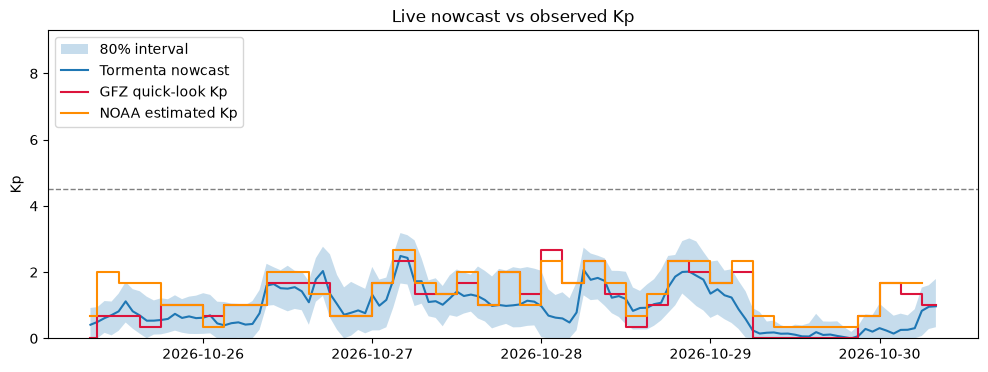

In [5]:
ev.plot_live(live, "16_live_nowcast")
plt.show()